**Student Name: Muneeb Rifaq**

**Student ID: 45 45 38**

# **Lab 9-Semantic Image Segmentation**


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Instructor:** Dr. Muhammad Daud Abdullah &nbsp;|&nbsp; **Lab Engineer:** Ms. Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** _______________

### Introduction

**Semantic segmentation** gives a class label to **every pixel** of an image. Image classification
says *what* is in a picture; segmentation also says *where*, pixel by pixel. It is used in
self-driving cars, medical imaging and robotics.

In this lab you will segment car images into 5 classes (background, car, wheel, light, window)
using a **U-Net**. A U-Net has three parts:

- an **encoder** that shrinks the image and learns *what* is in it;
- a **decoder** that grows it back to full size and learns *where* it is;
- **skip connections** that copy fine detail from the encoder to the decoder.

We use a U-Net whose encoder (VGG16-BN) is **already pretrained on ImageNet**, so it learns
quickly even from a small dataset.

### What you will do

| Task | What
|------|------
| 0 | Set up and download the dataset
| 1 | Look at the images and masks
| 2 | Understand the data pipeline
| 3 | Create the U-Net model
| 4 | Train, and try one change
| 5 | Test and look at predictions
| | Write your answers

**Before you start:** use a GPU. In Colab: *Runtime &rarr; Change runtime type &rarr; T4 GPU*.

**Submission.** Run everything from top to bottom, write your answers in the **Answer** cells,
and save the notebook with all outputs. This is an **individual** lab; plagiarism is not allowed.

</div>


## Task 0 &mdash; Setup and dataset  

> **The dataset.** The **Car Segmentation** dataset contains 211 images of cars (mostly side
> views) and their masks. An image and its mask have the **same file name** (for example
> `003.png` in `masks` belongs to `003.png` in `images`). Every pixel of a mask holds the class
> of the same pixel in the image:
>
> | value | class |
> |-------|-------|
> | 0 | background |
> | 1 | car |
> | 2 | wheel |
> | 3 | light |
> | 4 | windows |
>
> Source: https://www.kaggle.com/datasets/intelecai/car-segmentation

**Task 0.1.** Run the three cells below. The first installs the libraries and imports them, the
second downloads the dataset, the third finds the `images` and `masks` folders.

**If the download cell fails (Option B):** open the Kaggle link above, click *Download*, upload
the zip to Colab (left panel &rarr; Files), run `!unzip -q car-segmentation.zip -d /content/car-segmentation`,
and then set `path = "/content/car-segmentation"` in the third cell instead of running the
second cell.


In [3]:
!pip install -q segmentation-models-pytorch kagglehub

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import albumentations as A
import segmentation_models_pytorch as smp
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cpu":
    print("WARNING: no GPU found. Training will be very slow. Change the runtime type to a T4 GPU.")


Device: cuda


In [4]:
import kagglehub
path = kagglehub.dataset_download("intelecai/car-segmentation")
print("Dataset downloaded to:", path)


Using Colab cache for faster access to the 'car-segmentation' dataset.
Dataset downloaded to: /kaggle/input/car-segmentation


In [5]:
def find_folder(root, name):
    """Search the downloaded dataset for a folder with the given name."""
    for dirpath, dirnames, _ in os.walk(root):
        if name in dirnames:
            return os.path.join(dirpath, name) + "/"
    raise FileNotFoundError(f"Folder '{name}' not found under {root}")

IMAGE_PATH = find_folder(path, "images")
MASK_PATH = find_folder(path, "masks")
n_classes = 5

ids = sorted(f.split(".")[0] for f in os.listdir(IMAGE_PATH) if f.endswith(".png"))
print("Images folder:", IMAGE_PATH)
print("Masks folder :", MASK_PATH)
print("Total images :", len(ids))


Images folder: /kaggle/input/car-segmentation/car-segmentation/images/
Masks folder : /kaggle/input/car-segmentation/car-segmentation/masks/
Total images : 211


## Task 1 &mdash; Look at the data  

**Task 1.1.** The helper `show_sample` draws an image, its mask, and the mask laid over the
image. Call it for **three different indices** of your choice (for example 5, 50, 100).

**Task 1.2.** Print the shape of one image and one mask, and the **unique values** inside one
mask (`np.unique`).


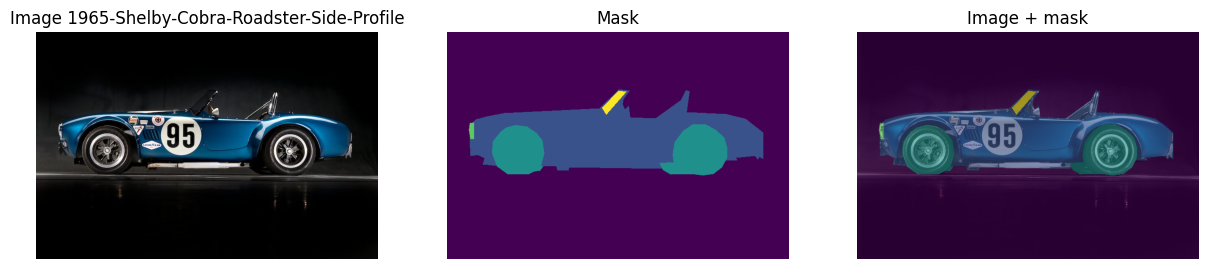

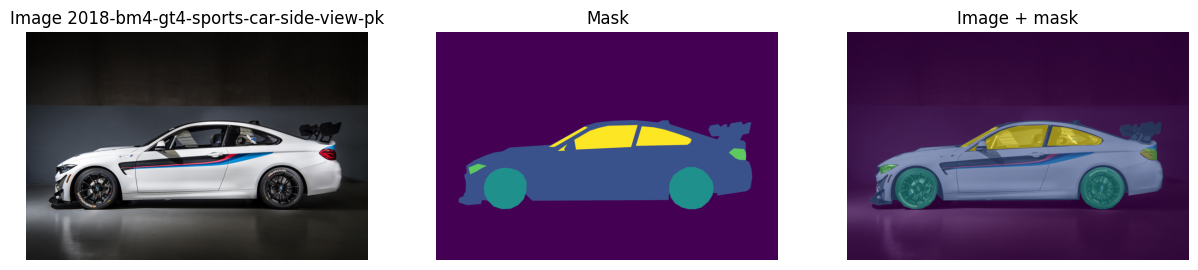

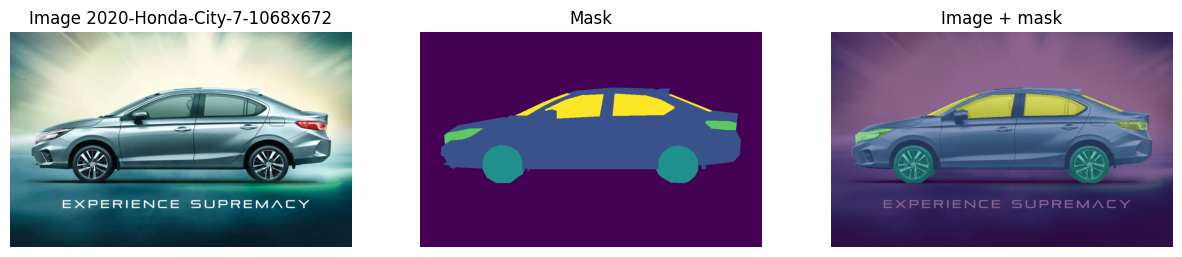

In [6]:
def show_sample(i):
    img = cv2.cvtColor(cv2.imread(IMAGE_PATH + ids[i] + ".png"), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(MASK_PATH + ids[i] + ".png", cv2.IMREAD_GRAYSCALE)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].imshow(img); ax[0].set_title("Image " + ids[i])
    ax[1].imshow(mask, vmin=0, vmax=4); ax[1].set_title("Mask")
    ax[2].imshow(img); ax[2].imshow(mask, alpha=0.6, vmin=0, vmax=4); ax[2].set_title("Image + mask")
    for a in ax: a.axis("off")
    plt.show()

# TODO 1.1 — call show_sample(...) for three different indices
show_sample(5)
show_sample(10)
show_sample(15)

# TODO 1.2 — print the shape of one image and one mask, and np.unique of one mask


### Question 1

Look at the masks. **How does a mask store the information about the different parts of a car?**
(What does one pixel of a mask contain, and what is the shape of a mask compared with its image?)

**Answer 1:**

**How does a mask store the information about the different parts of a car?**
Sol: The Mask reprsents the different parts of a car such as the windows, body, lights and tyres by classifying each individual image pixel to a specific class using different colors.


**What does one pixel of a mask contain?**
Sol: Every pixel of the mask is set to a specific color and all pixels that belong to a specific part of the car are set to the same color. The tyres are violet, lights are green, windows are yellow and the body is blue.


**What is the shape of a mask compared with its image?**
Sol: The shape of the mask parts are the same as the part of the car that they are masking(tyre, lights, car body).



## Task 2 &mdash; The data pipeline  

> **Concept.** Three things happen before the images reach the network:
>
> 1. **Split.** The data is divided into training (about 76%), validation (about 14%) and test
>    (about 10%) sets. The test set is used only at the end.
> 2. **Dataset class.** `CarDataset` reads one image and its mask, applies the augmentations,
>    **normalises** the image, and returns an image tensor and a mask tensor. The method that
>    returns one item is `__getitem__`.
> 3. **DataLoader.** It groups the items into batches (here 8 images).
>
> The augmentations (random horizontal flip, random brightness and contrast) are applied only to
> the training images. All images and masks are resized to 256 &times; 256.

**Task 2.1.** Run the cell below.

**Task 2.2.** Take one batch from `train_loader` and print the shape of the images and of the
masks.


In [7]:
IMG_SIZE = 256
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # ImageNet statistics

X_trainval, X_test = train_test_split(ids, test_size=0.1, random_state=19)
X_train, X_val = train_test_split(X_trainval, test_size=0.15, random_state=19)
print("Train:", len(X_train), " Validation:", len(X_val), " Test:", len(X_test))

class CarDataset(Dataset):
    def __init__(self, names, transform=None):
        self.names, self.transform = names, transform
        self.to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        img = cv2.cvtColor(cv2.imread(IMAGE_PATH + self.names[idx] + ".png"), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(MASK_PATH + self.names[idx] + ".png", cv2.IMREAD_GRAYSCALE)
        if self.transform is not None:
            out = self.transform(image=img, mask=mask)
            img, mask = out["image"], out["mask"]
        return self.to_tensor(img), torch.from_numpy(mask).long()

t_train = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE), A.HorizontalFlip(p=0.5), A.RandomBrightnessContrast(p=0.3)])
t_eval = A.Compose([A.Resize(IMG_SIZE, IMG_SIZE)])

train_set = CarDataset(X_train, t_train)
val_set = CarDataset(X_val, t_eval)
test_set = CarDataset(X_test, t_eval)

batch_size = 8
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False)

# TODO 2.2 — take one batch (images, masks) from train_loader and print their shapes
images, masks = next(iter(train_loader))
print("Images shape:", images.shape)
print("Masks shape:", masks.shape)


Train: 160  Validation: 29  Test: 22
Images shape: torch.Size([8, 3, 256, 256])
Masks shape: torch.Size([8, 256, 256])


### Questions 2 to 4

**Question 2.** When we retrieve an item from a `CarDataset` object (for example `train_set[0]`),
which method is called, and what does the item consist of (what is each part, and what are
their shapes)?

**Question 3.** Where do the numbers in `MEAN` and `STD` come from, and why do we normalise the
images with them?

**Question 4.** Which augmentations are used here? Why are they applied to the training images
only, and not to the validation and test images?
___________________________________________________________
**Answer 2:**

Sol: The function called __getitem__(self, idx) and the tupule consists of 2 elements (transformed_image: [3, 256, 256], mask_tensor [256, 256]).

_________________________________________________________________
**Answer 3:**

*Sol:*

The MEAN numbers [0.485, 0.456, 0.406] represent RGB means and the STD numbers [0.229, 0.224, 0.225] reresent RGB standard deviation

They are computed globally across millions of images in the ImageNet dataset.

We normalize the data for:

**Faster and Stable Convergence**: Neural network optimization relies on gradient descent. Centering the input data around zero with a standard deviation of 1 prevents exploding or vanishing gradients and helps optimizers find the minimum loss much faster.
_______________________________________________________________
**Answer 4:**

Sol:

The training data was applied by the augmentations
1: Resize(): which changes the size of the image to the chosen length and width (255 x 255 pixels).
2: HorizontalFlip(): which horizontally rotate the image a set angle(90 degrees) and has a 50% chance of triggering.
3: RandomBrightnessContrast(): Every time an image passes through the transform, there is a 30% chance the effect runs and a 70% chance the image is left untouched.

**Why they are used in the training set:**

They are used to artificially increase the diversity of the training data in order to better simulate real world conditions and forces the model to not focus on trivial details but learn robust patterns and invariant features like being able to recognise a car no matter what direction it is parked or what angle the picture was taken in wether tilted, upside down, at an angle or from above.

**Why they are not used in Validation and Test:**

Evaluation datasets must remain unbiased, deterministic, and representative of real-world deployment data. Altering validation/test images would distort performance metrics and make it impossible to obtain a reliable, consistent measure of how well the model truly generalizes.

## Task 3 &mdash; The U-Net model  

> **Concept.** The library `segmentation_models_pytorch` (`smp`) builds a ready-made U-Net. We
> choose the encoder, here **VGG16-BN**, with weights **pretrained on ImageNet**. The output
> has 5 channels (one score per class) for every pixel; no softmax is applied inside the model
> (`activation=None`), because the loss function does it.
>
> Library: https://github.com/qubvel/segmentation_models.pytorch

**Task 3.1.** Create the model with `make_model()` and move it to the device.

**Task 3.2.** Print the total number of parameters, and pass one batch of images through the
model. Print the shape of the output. (Expected: `[8, 5, 256, 256]`, that is batch, classes,
height, width.)


In [8]:
def make_model():
    return smp.Unet("vgg16_bn", encoder_weights="imagenet", classes=n_classes, activation=None,
                    encoder_depth=5, decoder_channels=[256, 128, 64, 32, 16])

# TODO 3.1 — model = make_model().to(device)
model = make_model().to(device)
# TODO 3.2 — the number of parameters, and the output shape for one batch from train_loader
total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", total_params)
images, masks = next(iter(train_loader))
output = model(images.to(device))
print("Output shape:", output.shape)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  554MB            

model.safetensors: downloading bytes:           |  0.00B            

Total parameters: 23757269
Output shape: torch.Size([8, 5, 256, 256])


### Question 5

The library offers many encoders besides `vgg16_bn` (see the link above, in the section on
encoders). **Name three other encoders. If you had to replace VGG16-BN, which one would you
choose, and why?** (There is no single correct answer; give a reason.)

**Answer 5:**:

**Three Other Available Encoders**

resnet34 (or resnet50):
Residual networks featuring skip connections that prevent vanishing gradients, offering an excellent balance of speed and accuracy.

efficientnet-b0:
Highly optimized architectures scaled using compound scaling to maximize performance while minimizing parameter count.

mobilenet_v2:
Lightweight architectures designed specifically for efficiency, making them ideal for mobile or resource-constrained edge devices.


**Replacement Choice and Justification**

Choice: resnet34

VGG16-BN is notoriously heavy, containing a massive number of fully connected layer parameters and feature channels that make it memory-intensive and slow to train. Replacing it with resnet34 provides a superior trade-off: it uses shortcut connections that ease gradient flow, converges faster, requires significantly less GPU memory, and typically achieves equal or better segmentation performance (mIoU) with a fraction of the computational cost.

## Task 4 &mdash; Metrics and training

> **Concept.** We measure two things on every batch:
>
> - **Pixel accuracy** = correct pixels / all pixels.
> - **mean IoU (mIoU)**: for every class, IoU = (pixels both predicted and true) / (pixels
>   predicted or true); then the average over the classes.
>
> The loss is the **cross-entropy** over the 5 classes for every pixel. The optimiser is
> **Adam**. After every epoch the model is checked on the validation set, and the weights with
> the **best validation mIoU** are saved.

**Task 4.1.** Run the cell with the metrics and the training function.

**Task 4.2.** Train the model of Task 3 with `lr = 0.001` for `epochs = 10` by calling
`train(model, lr, epochs, "best_run1.pth")`. It prints one line per epoch and returns the history.

**Task 4.3.** Plot the training and validation curves with `plot_history`.

**Task 4.4 (one experiment).** Change **one** hyperparameter (for example `lr = 0.0001`, or
`epochs = 15`, or the batch size) and train a **new** model (`make_model().to(device)`), saving to
`"best_run2.pth"`. Fill in the small table below with the best validation mIoU of both runs.

| Run | What changed | Best validation mIoU |
|-----|--------------|----------------------|
| 1   | (default)    |                      |
| 2   |              |                      |


In [9]:
def pixel_accuracy(output, mask):
    with torch.no_grad():
        pred = torch.argmax(output, dim=1)
        return (pred == mask).float().mean().item()

def mean_iou(output, mask, smooth=1e-10):
    with torch.no_grad():
        pred = torch.argmax(output, dim=1).reshape(-1)
        mask = mask.reshape(-1)
        ious = []
        for c in range(n_classes):
            p, t = pred == c, mask == c
            if t.sum() == 0:                       # class not present in the ground truth: skip it
                continue
            inter = (p & t).sum().float()
            union = (p | t).sum().float()
            ious.append(((inter + smooth) / (union + smooth)).item())
        return float(np.mean(ious))

loss_fn = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    """One pass over a loader. Trains if an optimizer is given, otherwise only evaluates."""
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss = total_acc = total_iou = 0.0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = loss_fn(outputs, masks)
        if training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_loss += loss.item()
        total_acc += pixel_accuracy(outputs, masks)
        total_iou += mean_iou(outputs, masks)
    n = len(loader)
    return total_loss / n, total_acc / n, total_iou / n

def train(model, lr, epochs, ckpt_path):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "train_iou": [], "val_iou": []}
    best_iou = -1
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tl, ta, ti = run_epoch(model, train_loader, optimizer)
        vl, va, vi = run_epoch(model, val_loader)
        for k, v in zip(hist, (tl, vl, ta, va, ti, vi)):
            hist[k].append(v)
        if vi > best_iou:
            best_iou = vi
            torch.save(model.state_dict(), ckpt_path)
        print(f"epoch {epoch:2d}/{epochs}  train loss {tl:.3f} mIoU {ti:.3f} | val loss {vl:.3f} acc {va:.3f} mIoU {vi:.3f}  ({time.time() - t0:.0f}s)")
    print("best validation mIoU:", round(best_iou, 3))
    return hist

def plot_history(hist, title=""):
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    for a, key, label in zip(ax, ["loss", "acc", "iou"], ["Loss", "Pixel accuracy", "mIoU"]):
        a.plot(hist["train_" + key], label="train"); a.plot(hist["val_" + key], label="validation")
        a.set_xlabel("epoch"); a.set_ylabel(label); a.set_title(title + " " + label); a.legend()
    plt.tight_layout(); plt.show()


epoch  1/10  train loss 1.003 mIoU 0.364 | val loss 1.959 acc 0.626 mIoU 0.271  (26s)
epoch  2/10  train loss 0.405 mIoU 0.507 | val loss 0.426 acc 0.882 mIoU 0.469  (22s)
epoch  3/10  train loss 0.223 mIoU 0.652 | val loss 0.222 acc 0.932 mIoU 0.643  (20s)
epoch  4/10  train loss 0.167 mIoU 0.678 | val loss 0.187 acc 0.942 mIoU 0.663  (21s)
epoch  5/10  train loss 0.155 mIoU 0.678 | val loss 0.210 acc 0.931 mIoU 0.646  (21s)
epoch  6/10  train loss 0.122 mIoU 0.697 | val loss 0.130 acc 0.956 mIoU 0.686  (20s)
epoch  7/10  train loss 0.104 mIoU 0.707 | val loss 0.155 acc 0.950 mIoU 0.680  (20s)
epoch  8/10  train loss 0.095 mIoU 0.714 | val loss 0.115 acc 0.960 mIoU 0.694  (20s)
epoch  9/10  train loss 0.108 mIoU 0.713 | val loss 0.228 acc 0.924 mIoU 0.655  (20s)
epoch 10/10  train loss 0.110 mIoU 0.716 | val loss 0.696 acc 0.812 mIoU 0.429  (20s)
best validation mIoU: 0.694


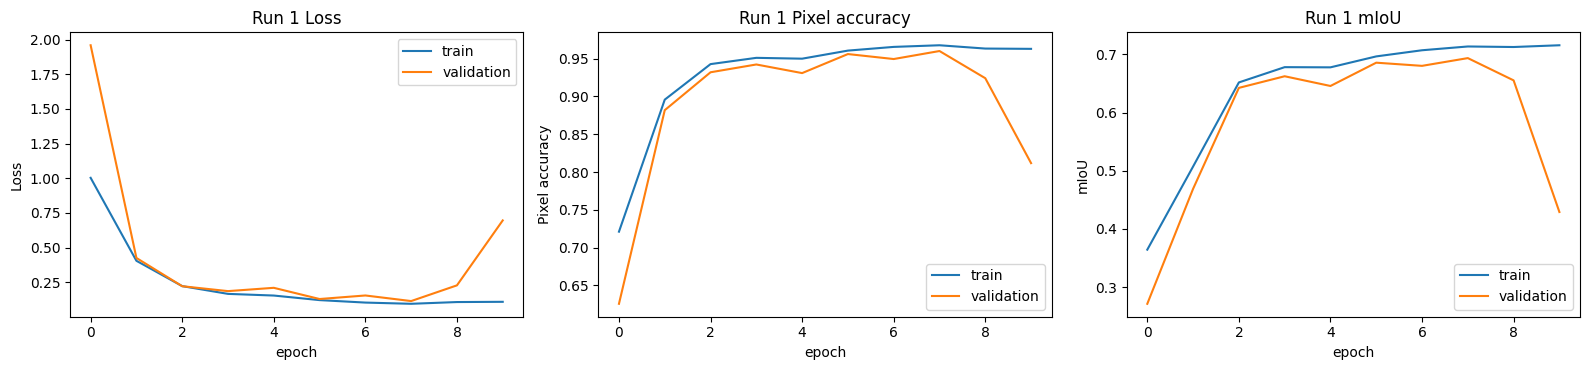

epoch  1/10  train loss 0.921 mIoU 0.291 | val loss 0.730 acc 0.819 mIoU 0.408  (20s)
epoch  2/10  train loss 0.510 mIoU 0.530 | val loss 0.431 acc 0.923 mIoU 0.612  (20s)
epoch  3/10  train loss 0.367 mIoU 0.634 | val loss 0.326 acc 0.941 mIoU 0.646  (20s)
epoch  4/10  train loss 0.287 mIoU 0.668 | val loss 0.275 acc 0.948 mIoU 0.663  (21s)
epoch  5/10  train loss 0.240 mIoU 0.683 | val loss 0.243 acc 0.949 mIoU 0.663  (20s)
epoch  6/10  train loss 0.214 mIoU 0.689 | val loss 0.213 acc 0.956 mIoU 0.679  (20s)
epoch  7/10  train loss 0.191 mIoU 0.697 | val loss 0.193 acc 0.958 mIoU 0.682  (21s)
epoch  8/10  train loss 0.168 mIoU 0.707 | val loss 0.176 acc 0.961 mIoU 0.693  (20s)
epoch  9/10  train loss 0.156 mIoU 0.715 | val loss 0.168 acc 0.961 mIoU 0.695  (21s)
epoch 10/10  train loss 0.138 mIoU 0.722 | val loss 0.156 acc 0.962 mIoU 0.697  (20s)
best validation mIoU: 0.697


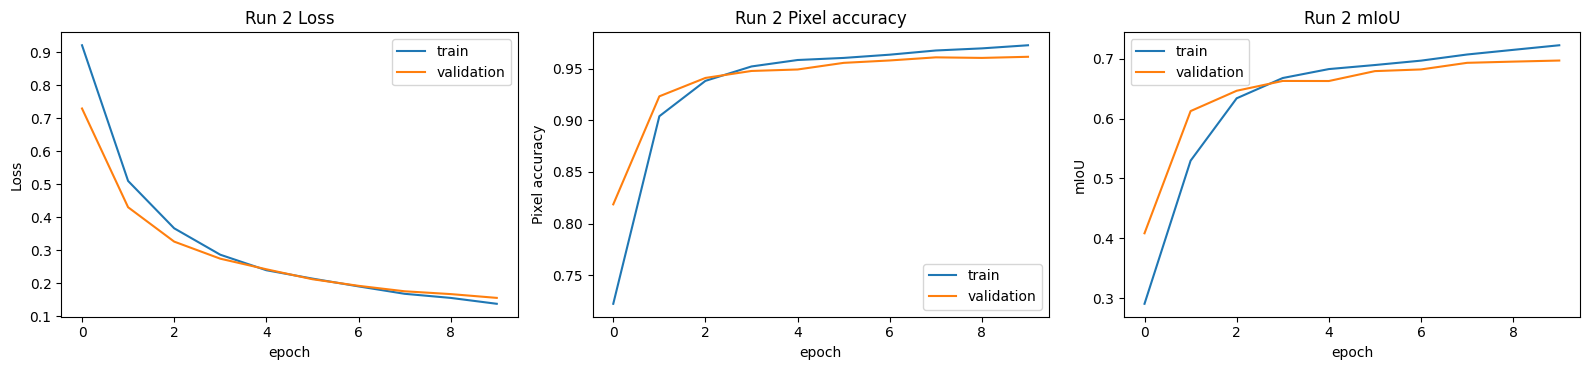

In [10]:
# TODO 4.2 — lr = 0.001; epochs = 10; history1 = train(model, lr, epochs, "best_run1.pth")
lr = 0.001
epochs = 10
history1 = train(model, lr, epochs, "best_run1.pth")
# TODO 4.3 — plot_history(history1, "Run 1")
plot_history(history1, "Run 1")
# TODO 4.4 — change ONE hyperparameter, make a NEW model, train it, and plot:
#            model2 = make_model().to(device)
#            history2 = train(model2, ..., ..., "best_run2.pth")
#            plot_history(history2, "Run 2")
new_lr = 0.0001
model2 = make_model().to(device)
history2 = train(model2, new_lr, epochs, "best_run2.pth")
plot_history(history2, "Run 2")


Table of Best Validation MIOU:
__________________________________________________________________
epoch 1:  train loss 0.921 mIoU 0.291 | val loss 0.730 acc 0.819 mIoU 0.408
__________________________________________________________________
epoch 2:  train loss 0.510 mIoU 0.530 | val loss 0.431 acc 0.923 mIoU 0.612
__________________________________________________________________
epoch 3:  train loss 0.367 mIoU 0.634 | val loss 0.326 acc 0.941 mIoU 0.646
__________________________________________________________________
epoch 4:  train loss 0.287 mIoU 0.668 | val loss 0.275 acc 0.948 mIoU 0.663
__________________________________________________________________
epoch 5:  train loss 0.240 mIoU 0.683 | val loss 0.243 acc 0.949 mIoU 0.663
__________________________________________________________________
epoch 6:  train loss 0.214 mIoU 0.689 | val loss 0.213 acc 0.956 mIoU 0.679
__________________________________________________________________
epoch 7:  train loss 0.191 mIoU 0.697 | val loss 0.193 acc 0.958 mIoU 0.682
__________________________________________________________________
epoch 8:  train loss 0.168 mIoU 0.707 | val loss 0.176 acc 0.961 mIoU 0.693
__________________________________________________________________
epoch 9:  train loss 0.156 mIoU 0.715 | val loss 0.168 acc 0.961 mIoU 0.695
__________________________________________________________________
epoch 10: train loss 0.138 mIoU 0.722 | val loss 0.156 acc 0.962 mIoU 0.697
__________________________________________________________________
best validation mIoU: 0.697

### Questions 6 and 7

**Question 6.** Pixel accuracy and mIoU are both computed above. **What is the difference between
them, and which one is the better measure for this dataset? Why?** (Hint: what fraction of the
pixels in a typical image is background?)

**Question 7.** Look at your training plots. **Describe what you see** (does the loss go down? do
the training and validation curves stay close or separate? is the model still improving at the
last epoch?). **Which hyperparameter did you change in Task 4.4, and did it improve the best
validation mIoU?**

**Answer 6:**

**What is the difference between pixel accuracy and mIOU**
Pixel Accuracy: This measures the percentage of all pixels in the dataset that are correctly classified. It is calculated as the total number of correctly predicted pixels divided by the total number of pixels: Accuracy = [(TP+TN)/ (TP + TN + FP + FN)]

mIoU (Mean Intersection over Union): This measures the overlap between the predicted segmentation and the ground truth mask for each class separately, and then takes the unweighted average across all classes. For a given class, IoU is defined as the area of intersection divided by the area of union:

IOU = [(TP)/(TP + FP + FN)]

In a binary segmentation task (Car vs. Background), $\text{mIoU} = \frac{\text{IoU}_{\text{background}} + \text{IoU}_{\text{car}}}{2}$.

**Which one is the better measure for this dataset? Why?**

MIOU is the better fit for this model and trainig set as majority of the training images(75%) are of the background meaning a lazy and poorly trained/configured model could get 75% accuracy by just classifying everything as background. In order to prevent this miou is necessary for correcting severe class imbalance.
mIoU evaluates performance on a per-class basis rather than a per-pixel basis.

Because it calculates the intersection and union independently for the car class, it severely penalizes models that miss the car or misclassify its boundaries, ensuring that your metric reflects how well the model actually segments the car rather than just guessing the empty space around it.

**Answer 7:**

Sol:
In the loss fuction of the model during the training phase, the training and validation losss started high but gradually decreased as the no of training epochs increased. The difference between the training and validation loss curves also decreases until epoch 3, then the lines start to split and become different. At epoch 3 the validation loss increases slightly while the training loss remains mostly the same. At epoch 5 the validation loss decreases again and merges close to training loss and fluctuates slightly higher and lower until the epoch 7 when it starts increasing greatly.

Near the end both the validation losses is increasing so the model is not improving.

**Which hyperparameter did you change in Task 4.4, and did it improve the best validation mIoU?**

Sol:
I changed the learning rate from 0.001 to 0.0001, it slightly improved the best validation MIOU from 0.694 to 0.697, but the difference is very small.


## Task 5 &mdash; Test and look at the predictions  

> **Concept.** The test set was never used for training or for choosing the model. Here we load
> the weights with the best validation mIoU, measure the loss, pixel accuracy and mIoU on the
> test set, and compare the predicted masks with the true masks.

**Task 5.1.** Create a new model, load the weights of the run with the better validation mIoU
(`best_run1.pth` or `best_run2.pth`) with `load_state_dict`, and move it to the device.

**Task 5.2.** Evaluate it on the test set with `run_epoch(model, test_loader)` and print the three
numbers.

**Task 5.3.** The helper `show_prediction(model, idx)` shows an image, its true mask and the
predicted mask. Call it for **three** images of the test set (indices from 0 to
`len(test_set) - 1`).


Test loss:  0.14103422065575918  Test accuracy:  0.9686703284581503 Test IOU:  0.7137389138573834


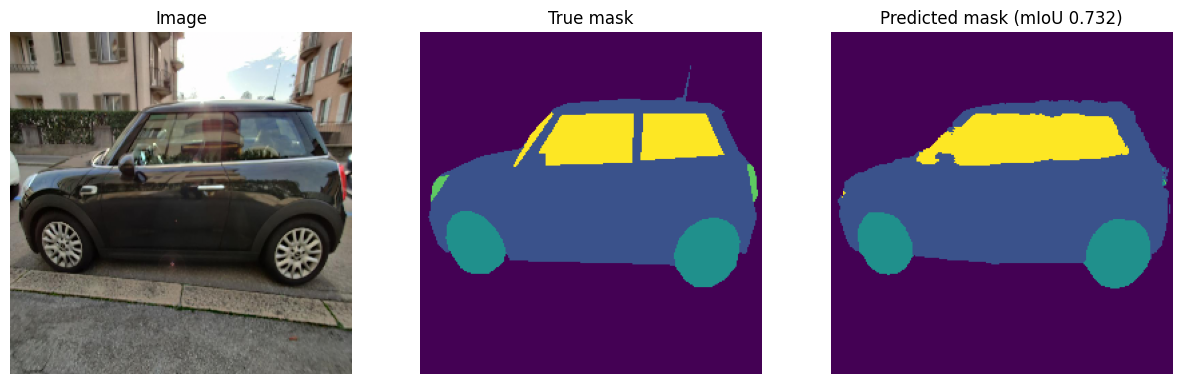

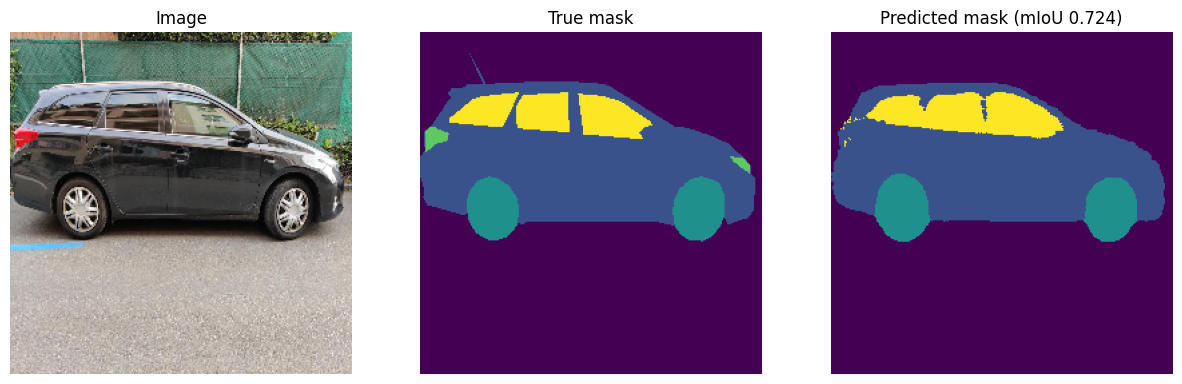

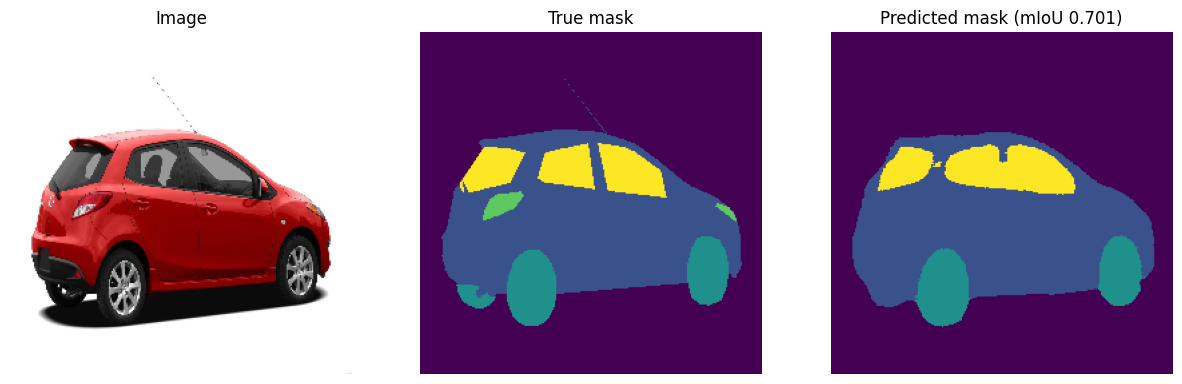

In [13]:
def show_prediction(model, idx):
    image, mask = test_set[idx]
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device)).cpu()
    pred = output.argmax(dim=1).squeeze(0)
    score = mean_iou(output, mask.unsqueeze(0))
    shown = image.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)      # undo the normalisation
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].imshow(shown.clamp(0, 1)); ax[0].set_title("Image")
    ax[1].imshow(mask, vmin=0, vmax=4); ax[1].set_title("True mask")
    ax[2].imshow(pred, vmin=0, vmax=4); ax[2].set_title(f"Predicted mask (mIoU {score:.3f})")
    for a in ax: a.axis("off")
    plt.show()

# TODO 5.1 — best_model = make_model(); best_model.load_state_dict(torch.load("best_run?.pth")); best_model.to(device)
best_model = make_model(); best_model.load_state_dict(torch.load("best_run2.pth")); best_model.to(device)
# TODO 5.2 — test_loss, test_acc, test_iou = run_epoch(best_model, test_loader); print them
test_loss, test_acc, test_iou = run_epoch(best_model, test_loader)
print("Test loss: ", test_loss, " Test accuracy: ", test_acc, "Test IOU: ", test_iou)
# TODO 5.3 — show_prediction(best_model, idx) for three indices
show_prediction(best_model, 0)
show_prediction(best_model, 1)
show_prediction(best_model, 2)




### Question 8

**Discuss your results.** Report the test pixel accuracy and the test mIoU. Compare them with the
validation mIoU of the same model. Looking at the predicted masks, **which classes does the model
segment well, and which ones does it get wrong?** Suggest one change that could improve the
result.
____________________________________________________________________
**Answer 8:**

Test pixel accuracy: 0.9686703284581503
Test IOU: 0.7137389138573834

Validation MIOU of the same model: 0.697
____________________________________________________________________
**Which classes does the model segment well**

The model map has very high performance in classification of the image background(PURPLE), the car body (BLUE) and the tyres(violet)

The model has medium performance in classifying the windows(yellow) as it fills in most of the space but the shapes and dividers still have distortions from the map itself


---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

### Before you submit

- [ ] The notebook runs from top to bottom with all outputs shown (Runtime &rarr; Restart and run all).
- [ ] Every `TODO` is done.
- [ ] Task 1: three samples are shown, and the shapes and unique mask values are printed.
- [ ] Task 4: the training curves of both runs are plotted, and the table of best validation mIoU is filled in.
- [ ] Task 5: the test result is printed, and three predictions are shown.
- [ ] Answers 1 to 8 are written in the **Answer** cells.
- [ ] This is an individual lab. Plagiarism is not allowed.

</div>
